In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from helpers import load_file

print("Loading data...")
X_train, y_train = load_file()
X_test, y_test = load_file('mnist_test.csv')
print("Data loaded.")

Loading data...
Data loaded.


Train shape: (60000, 784)
Test shape: (10000, 784)
Digit 7: 6265 samples
Digit 7: 6265 samples


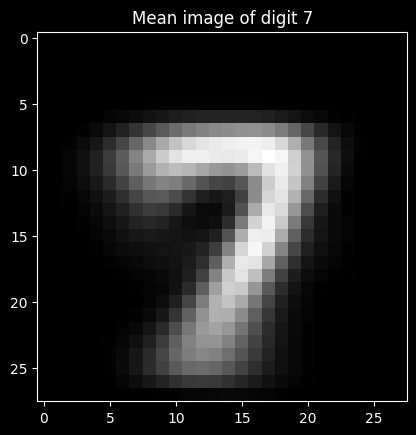

Covariance matrix shape: (784, 784)


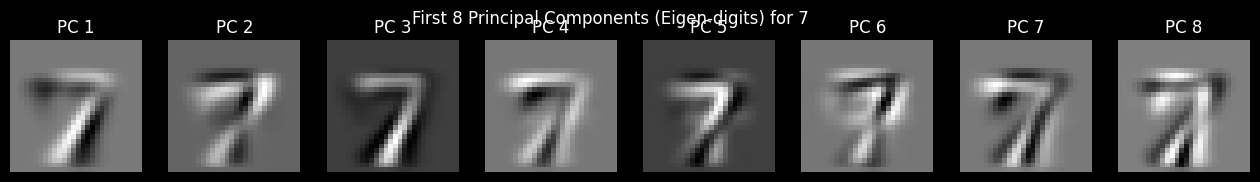

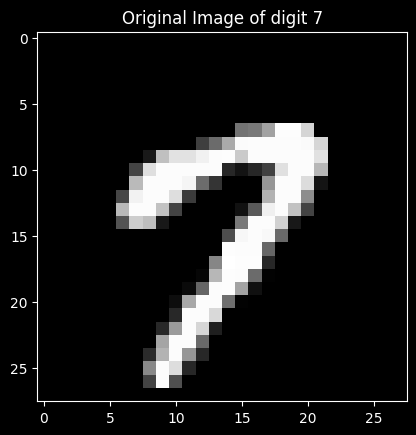

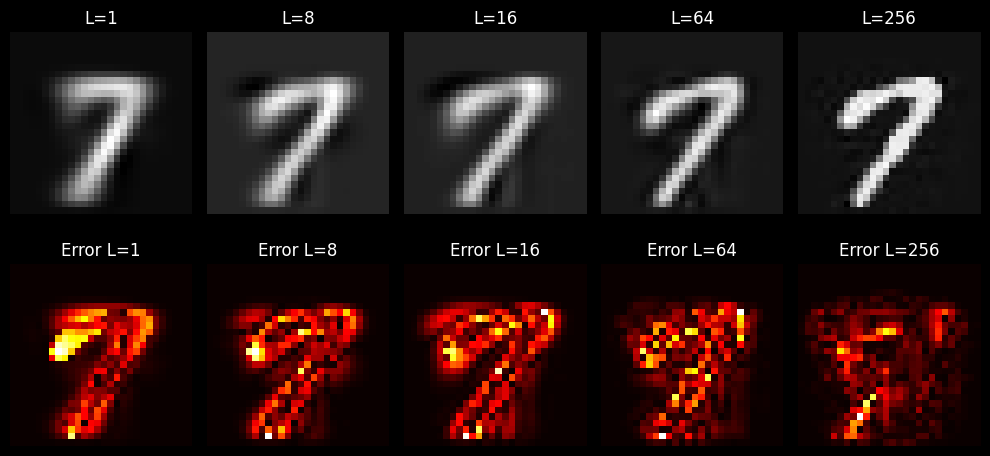

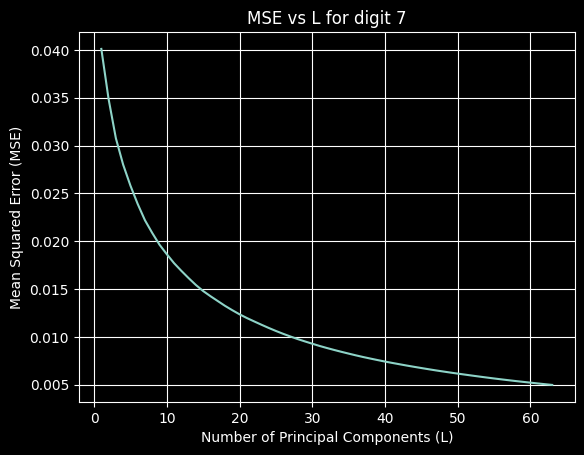

In [3]:
print(f"Train shape: {X_train.shape}") # Πρέπει να είναι (N, 784)
print(f"Test shape: {X_test.shape}")

digits = [7]

for d in digits:
    X_d = []
    for i in range(len(X_train)):
        if y_train[i] == d:
            X_d.append(X_train[i])
    X_d = np.array(X_d)
    print(f"Digit {d}: {X_d.shape[0]} samples")

    X_d = np.array(X_d)

    # Ερώτημα Α
    sum_vec = X_d.sum(axis=0)
    mean_vec = sum_vec / X_d.shape[0]
    print(f"Digit {d}: {X_d.shape[0]} samples")

    plt.imshow(mean_vec.reshape(28, 28), cmap='gray')
    plt.title(f"Mean image of digit {d}")
    plt.show()

    # Ερώτημα Β
    cov = np.cov(X_d, rowvar=False)
    print("Covariance matrix shape:", cov.shape)

    #Ερώτημα Γ
    pca_8 = PCA(n_components=8)
    pca_8.fit(X_d)

    components_8 = pca_8.components_
    plt.figure(figsize=(16, 2))
    plt.suptitle(f"First 8 Principal Components (Eigen-digits) for {d}")
    for i in range(8):
        plt.subplot(1, 8, i+1)
        plt.imshow(components_8[i].reshape(28, 28), cmap='gray')
        plt.title(f"PC {i+1}")
        plt.axis('off')
    plt.show()

    #Ερώτημα Δ
    L_values = [1, 8, 16, 64, 256]
    sample_idx = 0
    original_image = X_d[sample_idx]
    plt.imshow(original_image.reshape(28, 28), cmap='gray')
    plt.title(f"Original Image of digit {d}")
    plt.show()

    plt.figure(figsize=(len(L_values)*2, 5))
    for i, L in enumerate(L_values):
        pca_L = PCA(n_components=L)
        pca_L.fit(X_d)

        sample_reshaped = original_image.reshape(1, -1)
        reduced = pca_L.transform(sample_reshaped)
        reconstructed_image = pca_L.inverse_transform(reduced)

        difference_image = np.abs(original_image - reconstructed_image)

        plt.subplot(2, len(L_values), i+1)
        plt.imshow(reconstructed_image.reshape(28, 28), cmap='gray')
        plt.title(f"L={L}")
        plt.axis('off')

        plt.subplot(2, len(L_values), len(L_values) + i + 1)
        plt.imshow(difference_image.reshape(28, 28), cmap='hot') # 'hot' για να φαίνεται η ένταση του σφάλματος
        plt.title(f"Error L={L}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

    #Ερώτημα Ε

    mse_values = []
    L_range = range(1, 64)
    for L in L_range:
        pca_L = PCA(n_components=L)
        X_d_reduced = pca_L.fit_transform(X_d)
        X_d_reconstructed = pca_L.inverse_transform(X_d_reduced)

        mse = np.mean((X_d - X_d_reconstructed) ** 2)
        mse_values.append(mse)

    plt.plot(L_range, mse_values)
    plt.title(f"MSE vs L for digit {d}")
    plt.xlabel("Number of Principal Components (L)")
    plt.ylabel("Mean Squared Error (MSE)")
    plt.grid()
    plt.show()




Train MSE with L=128: 0.0042720752286770315


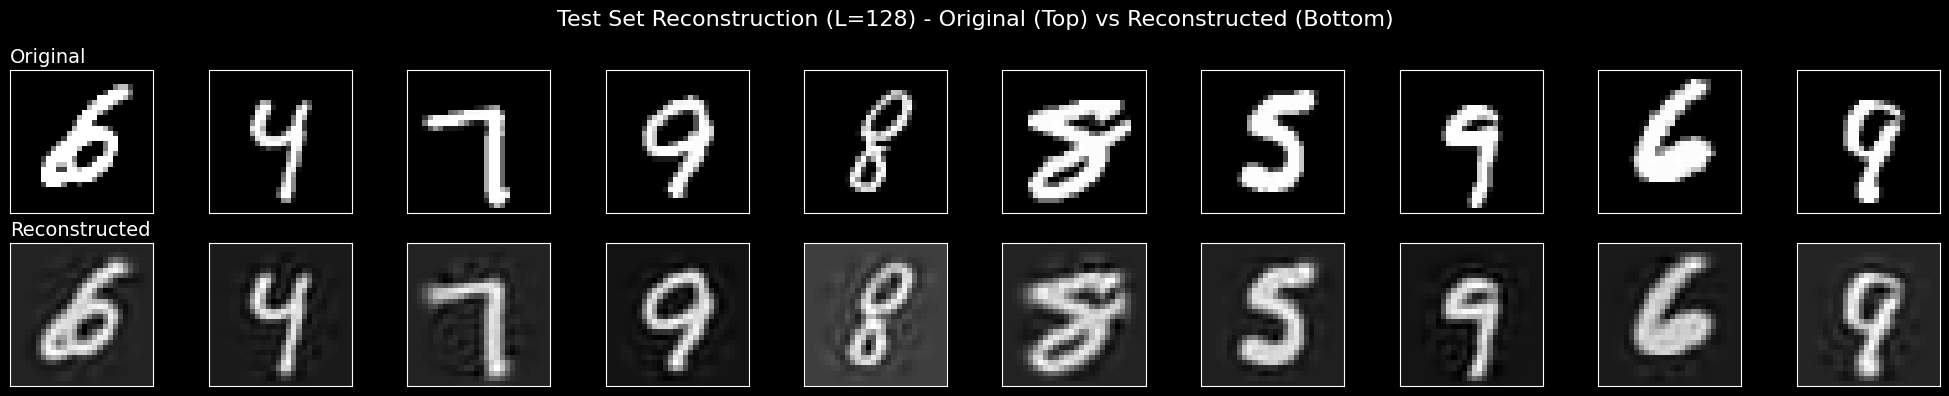

In [4]:
L = 128
pca_128 = PCA(n_components=L)
pca_128.fit(X_train)
VL = pca_128.components_

X_train_reduced = pca_128.transform(X_train)
X_train_reconstructed = pca_128.inverse_transform(X_train_reduced)
mse_train = np.mean((X_train - X_train_reconstructed) ** 2)
print(f"Train MSE with L={L}: {mse_train}")

X_test_reduced = pca_128.transform(X_test)
X_test_reconstructed = pca_128.inverse_transform(X_test_reduced)
mse_test = np.mean((X_test - X_test_reconstructed) ** 2)

num_samples = 10
indices = np.random.choice(len(X_test), num_samples, replace=False)

plt.figure(figsize=(20, 4))
plt.suptitle(f"Test Set Reconstruction (L={L}) - Original (Top) vs Reconstructed (Bottom)", fontsize=16)

for i, idx in enumerate(indices):
    # Original Image
    ax = plt.subplot(2, num_samples, i + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    if i == 0: ax.set_title("Original", fontsize=14, loc='left')

    # Reconstructed Image
    ax = plt.subplot(2, num_samples, i + 1 + num_samples)
    plt.imshow(X_test_reconstructed[idx].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    if i == 0: ax.set_title("Reconstructed", fontsize=14, loc='left')

plt.tight_layout()
plt.show()

Training Autoencoder...
Epoch [5/40], Loss: 0.0958, Similarity with PCA: 0.0001
Epoch [10/40], Loss: 0.0862, Similarity with PCA: 0.0003
Epoch [15/40], Loss: 0.0831, Similarity with PCA: 0.0011
Epoch [20/40], Loss: 0.0816, Similarity with PCA: 0.0015
Epoch [25/40], Loss: 0.0810, Similarity with PCA: 0.0020
Epoch [30/40], Loss: 0.0806, Similarity with PCA: 0.0023
Epoch [35/40], Loss: 0.0804, Similarity with PCA: 0.0023
Epoch [40/40], Loss: 0.0803, Similarity with PCA: 0.0024


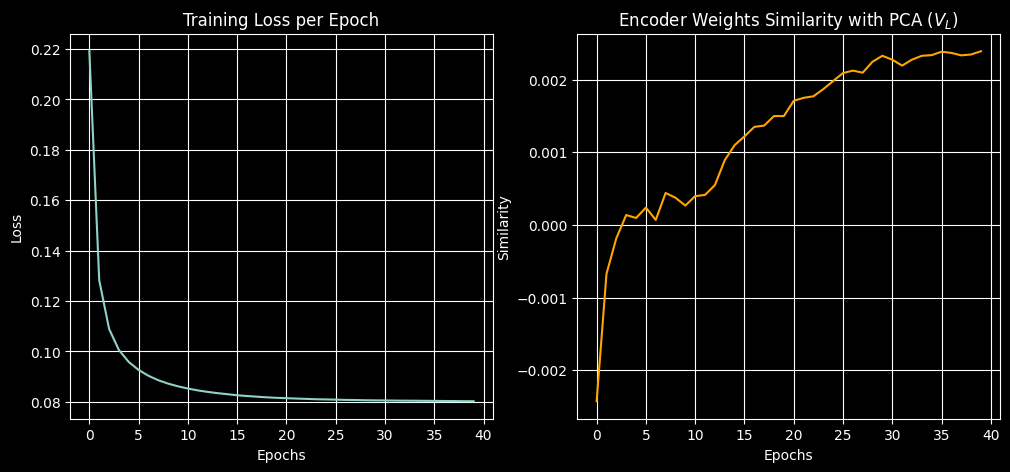

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
if X_train_tensor.max() > 1.0:
    X_train_tensor /= 255.0

dataset = TensorDataset(X_train_tensor, X_train_tensor) # Input = Target
dataloader = DataLoader(dataset, batch_size=250, shuffle=True)

X_numpy = X_train_tensor.numpy()
if len(X_numpy.shape) > 2:
    X_numpy = X_numpy.reshape(X_numpy.shape[0], -1)

X_centered = X_numpy - np.mean(X_numpy, axis=0)

pca = PCA(n_components=128)
pca.fit(X_centered)
V_L = pca.components_

class SimpleAE(nn.Module):
    def __init__(self):
        super(SimpleAE, self).__init__()
        # Encoder: 784 -> 128
        self.encoder = nn.Linear(784, 128, bias=False)
        # Decoder: 128 -> 784
        self.decoder = nn.Linear(128, 784, bias=False)
        self.activation = nn.Sigmoid()

    def forward(self, x):
        x = x.view(x.size(0), -1) # Flatten
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return self.activation(reconstructed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SimpleAE().to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

epochs = 40
similarity_metrics = []
losses = []

print("Training Autoencoder...")
for epoch in range(epochs):
    epoch_loss = 0
    for batch_idx, (data, _) in enumerate(dataloader):
        data = data.to(device)

        # Forward
        output = model(data)
        loss = criterion(output, data)

        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(dataloader)
    losses.append(avg_loss)


    #σύγκριση βαρών AE με PCA
    W_enc = model.encoder.weight.detach().cpu().numpy() # Shape: (128, 784)
    v_flat = V_L.flatten()
    w_flat = W_enc.flatten()
    similarity = np.dot(w_flat, v_flat) / (np.linalg.norm(w_flat) * np.linalg.norm(v_flat))
    similarity_metrics.append(similarity)

    if (epoch+1) % 5 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}, Similarity with PCA: {similarity:.4f}")


plt.figure(figsize=(12, 5))

# Loss Curve
plt.subplot(1, 2, 1)
plt.plot(losses, label='BCE Loss')
plt.title('Training Loss per Epoch')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid()

# Similarity Curve
plt.subplot(1, 2, 2)
plt.plot(similarity_metrics, color='orange', label='Cosine Similarity')
plt.title('Encoder Weights Similarity with PCA ($V_L$)')
plt.xlabel('Epochs')
plt.ylabel('Similarity')
plt.grid()

plt.show()



In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class StandardAE(nn.Module):
    def __init__(self):
        super(StandardAE, self).__init__()
        # Encoder (3 Layers)
        self.enc1 = nn.Linear(784, 256)
        self.enc2 = nn.Linear(256, 128)
        self.enc3 = nn.Linear(128, 64)

        # Decoder (3 Layers)
        self.dec1 = nn.Linear(64, 128)
        self.dec2 = nn.Linear(128, 256)
        self.dec3 = nn.Linear(256, 784)

        self.activation = nn.LeakyReLU(0.2)
        # Στο τέλος Sigmoid για να έχουμε έξοδο 0-1 (όπως τα pixels)
        self.final_activation = nn.Sigmoid()

    def forward(self, x):
        x = x.view(x.size(0), -1) # Flatten

        # Encoder
        x = self.activation(self.enc1(x))
        x = self.activation(self.enc2(x))
        z = self.enc3(x) # Latent code (συνήθως χωρίς activation εδώ ή linear)

        # Decoder
        x = self.activation(self.dec1(z))
        x = self.activation(self.dec2(x))
        out = self.final_activation(self.dec3(x))

        return out

# Υπολογισμός παραμέτρων μέσω κώδικα για επαλήθευση
model_q2 = StandardAE()
total_params = sum(p.numel() for p in model_q2.parameters())
print(f"Total Parameters (Standard AE): {total_params}")

Total Parameters (Standard AE): 484944


In [11]:
class PinvAE(nn.Module):
    def __init__(self):
        super(PinvAE, self).__init__()
        # Ορίζουμε ΜΟΝΟ τον Encoder. Ο Decoder δεν έχει δικά του βάρη (weights).
        self.enc1 = nn.Linear(784, 256)
        self.enc2 = nn.Linear(256, 128)
        self.enc3 = nn.Linear(128, 64)

        # Ορίζουμε biases για τον Decoder (προαιρετικό αλλά βοηθάει)
        self.b1 = nn.Parameter(torch.zeros(128))
        self.b2 = nn.Parameter(torch.zeros(256))
        self.b3 = nn.Parameter(torch.zeros(784))

    def forward(self, x):
        # --- Encoder (Κανονικά) ---
        h1 = F.leaky_relu(self.enc1(x), 0.2)
        h2 = F.leaky_relu(self.enc2(h1), 0.2)
        z  = self.enc3(h2)

        # --- Decoder (Με Ψευδοαντίστροφο) ---
        # Υπολογίζουμε δυναμικά το pinv των βαρών του Encoder
        w3_inv = torch.linalg.pinv(self.enc3.weight)
        w2_inv = torch.linalg.pinv(self.enc2.weight)
        w1_inv = torch.linalg.pinv(self.enc1.weight)

        # Περνάμε τα δεδομένα χρησιμοποιώντας τα pinv βάρη
        # F.linear(input, weight, bias)
        d1 = F.leaky_relu(F.linear(z, w3_inv, self.b1), 5.0)  # Κλίση 5.0 (αντίστροφη του 0.2)
        d2 = F.leaky_relu(F.linear(d1, w2_inv, self.b2), 5.0)
        out = torch.sigmoid(F.linear(d2, w1_inv, self.b3))

        return out


== Training AE #1 ==
epoch 01/10 | train MSE: 0.052296
epoch 02/10 | train MSE: 0.021810
epoch 03/10 | train MSE: 0.015087
epoch 04/10 | train MSE: 0.012069
epoch 05/10 | train MSE: 0.010342
epoch 06/10 | train MSE: 0.009197
epoch 07/10 | train MSE: 0.008380
epoch 08/10 | train MSE: 0.007725
epoch 09/10 | train MSE: 0.007225
epoch 10/10 | train MSE: 0.006820

== Training AE #2 ==
epoch 01/10 | train MSE: 0.066169
epoch 02/10 | train MSE: 0.032429
epoch 03/10 | train MSE: 0.022901
epoch 04/10 | train MSE: 0.017660
epoch 05/10 | train MSE: 0.014616
epoch 06/10 | train MSE: 0.012772
epoch 07/10 | train MSE: 0.011508
epoch 08/10 | train MSE: 0.010469
epoch 09/10 | train MSE: 0.009685
epoch 10/10 | train MSE: 0.008999

== Training AE #3 ==
epoch 01/10 | train MSE: 0.027502
epoch 02/10 | train MSE: 0.009816
epoch 03/10 | train MSE: 0.007569
epoch 04/10 | train MSE: 0.006531
epoch 05/10 | train MSE: 0.005999
epoch 06/10 | train MSE: 0.005553
epoch 07/10 | train MSE: 0.005351
epoch 08/10 | tr

,AE,Test MSE
0,AE #3,0.005182
1,AE #1,0.006851
2,AE #2,0.008858


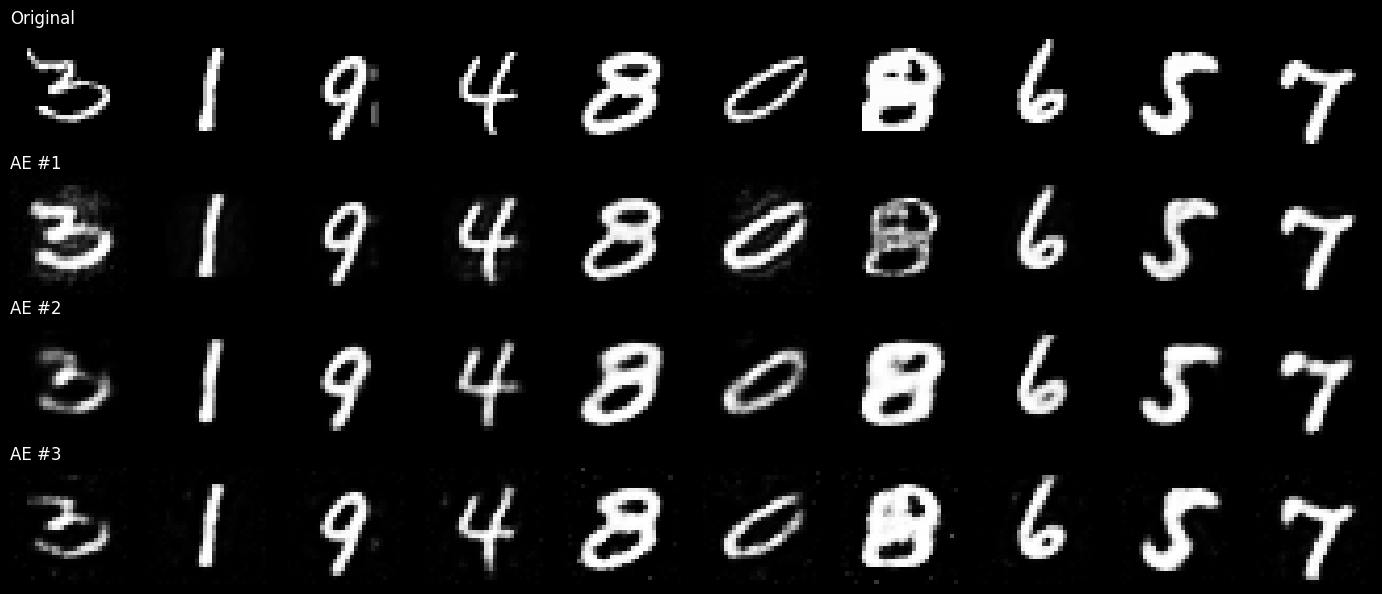

In [15]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Xtr = torch.tensor(X_train, dtype=torch.float32)
Xte = torch.tensor(X_test,  dtype=torch.float32)

# κανονικοποίηση 0-1
if Xtr.max() > 1.0: Xtr /= 255.0
if Xte.max() > 1.0: Xte /= 255.0

# flatten
Xtr = Xtr.view(Xtr.size(0), -1)
Xte = Xte.view(Xte.size(0), -1)

train_loader = DataLoader(TensorDataset(Xtr, Xtr), batch_size=256, shuffle=True)
test_loader  = DataLoader(TensorDataset(Xte, Xte), batch_size=512, shuffle=False)


def _model_out(model, x):
    """αν κάποιο forward επιστρέφει (recon, latent) κλπ, κράτα μόνο το recon"""
    y = model(x)
    return y[0] if isinstance(y, (tuple, list)) else y

def train_ae(model, train_loader, epochs=10, lr=1e-3):
    model = model.to(device).train()
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    for ep in range(epochs):
        total = 0.0
        for xb, _ in train_loader:
            xb = xb.to(device)
            opt.zero_grad()
            recon = _model_out(model, xb).view(xb.size(0), -1)
            loss = loss_fn(recon, xb)
            loss.backward()
            opt.step()
            total += loss.item() * xb.size(0)
        print(f"epoch {ep+1:02d}/{epochs} | train MSE: {total/len(train_loader.dataset):.6f}")
    return model

@torch.no_grad() # αποφυγή υπολογισμού γραφημάτων
def test_mse_and_recons(model, Xflat):
    model = model.to(device).eval()
    Xd = Xflat.to(device)
    recon = _model_out(model, Xd).view(Xd.size(0), -1).cpu()
    mse = torch.mean((Xflat.cpu() - recon) ** 2).item()
    return mse, recon

models = [
    ("AE #1", SimpleAE()),
    ("AE #2", StandardAE()),
    ("AE #3", PinvAE()),
]


trained = {}
for name, m in models:
    print("\n== Training", name, "==")
    trained[name] = train_ae(m, train_loader, epochs=10, lr=1e-3)

# Αξιολόγηση
rows = []
recons = {}
for name in trained:
    mse, recon = test_mse_and_recons(trained[name], Xte)
    rows.append([name, mse])
    recons[name] = recon

mse_df = pd.DataFrame(rows, columns=["AE", "Test MSE"]).sort_values("Test MSE").reset_index(drop=True)
display(mse_df)

# συγκεντρωτικά παραδείγματα (10 δείγματα)
idx = np.random.choice(len(Xte), 10, replace=False)

plt.figure(figsize=(14, 6))

# Original row
for j, k in enumerate(idx):
    ax = plt.subplot(4, 10, j + 1)
    ax.imshow(Xte[k].view(28, 28), cmap="gray")
    ax.axis("off")
    if j == 0: ax.set_title("Original", loc="left")

# Recon rows (3 AEs)
for i, name in enumerate(trained.keys(), start=1):
    for j, k in enumerate(idx):
        ax = plt.subplot(4, 10, i * 10 + j + 1)
        ax.imshow(recons[name][k].view(28, 28), cmap="gray")
        ax.axis("off")
        if j == 0: ax.set_title(name, loc="left")

plt.tight_layout()
plt.show()



--- Έναρξη Εκπαίδευσης VAE (100 Epochs) ---
Epoch: 1 | Average Loss: 203.6043
Epoch: 10 | Average Loss: 156.5094
Epoch: 20 | Average Loss: 151.0830
Epoch: 30 | Average Loss: 148.6397
Epoch: 40 | Average Loss: 147.1212
Epoch: 50 | Average Loss: 145.9370
Epoch: 60 | Average Loss: 145.1007
Epoch: 70 | Average Loss: 144.4138
Epoch: 80 | Average Loss: 143.8463
Epoch: 90 | Average Loss: 143.2700
Epoch: 100 | Average Loss: 142.8631

--- Παρουσίαση Εξέλιξης Γεννήτριας (Fixed Noise) ---


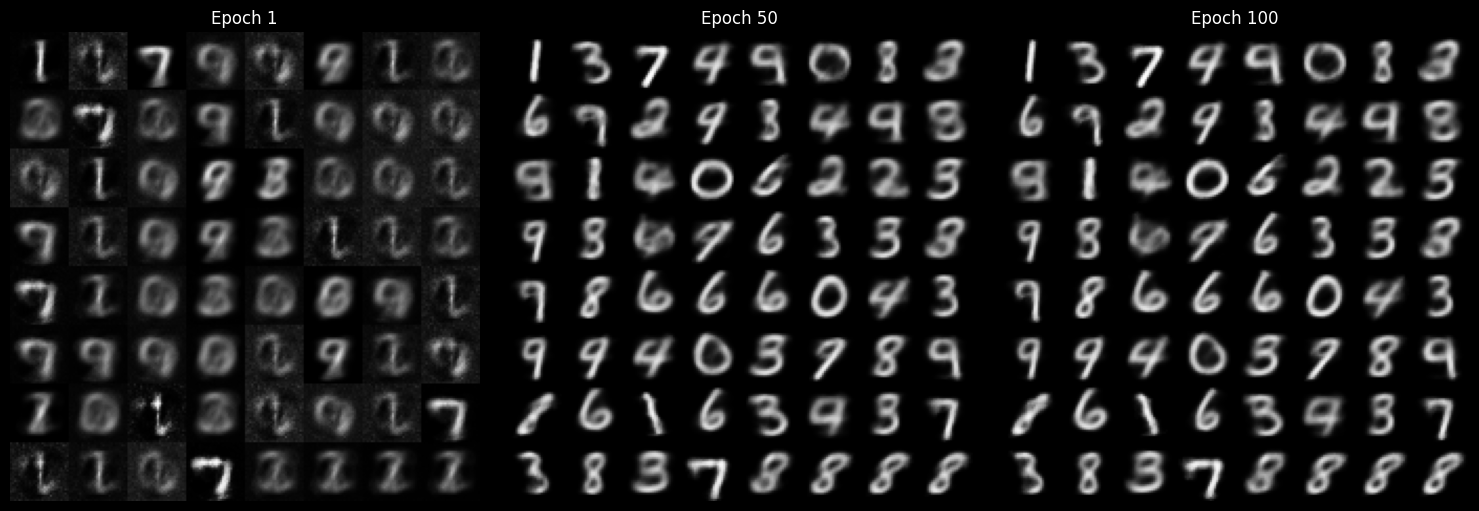


--- Δημιουργία Latent Space Scatter Plot ---


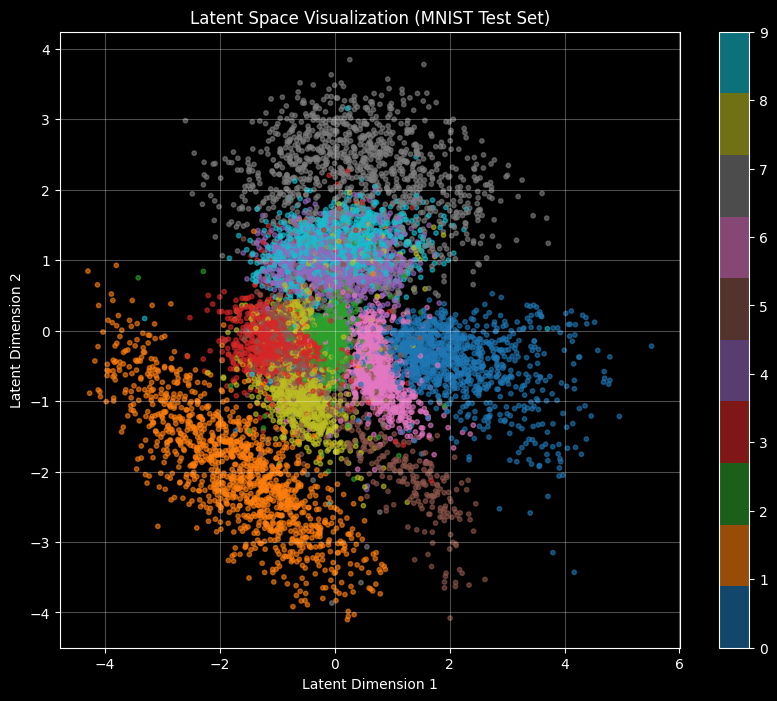

In [21]:
import torch.optim as optim

class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=2):
        super(VAE, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc2_logvar = nn.Linear(hidden_dim, latent_dim)

        self.fc3 = nn.Linear(latent_dim, hidden_dim)
        self.fc4 = nn.Linear(hidden_dim, input_dim)

    def encode(self, x):
        h1 = F.relu(self.fc1(x))
        return self.fc2_mu(h1), self.fc2_logvar(h1)

    def reparameterize(self, mu, logvar):
        # Reparameterization Trick: z = μ + σ * ε
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h3 = F.relu(self.fc3(z))
        return torch.sigmoid(self.fc4(h3)) # Sigmoid για BCE Loss (pixels 0-1)

    def forward(self, x):
        mu, logvar = self.encode(x.view(-1, 784))
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


def loss_function(recon_x, x, mu, logvar):
    #Reconstruction Loss (Binary Cross Entropy)
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction='sum')

    #KL Divergence (Πόσο απέχει η κατανομή από την Κανονική N(0,1))
    # Αναλυτικός τύπος: -0.5 * sum(1 + log(σ^2) - μ^2 - σ^2)
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return BCE + KLD

model = VAE().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
epochs = 100

# (α') Δημιουργία σταθερού θορύβου N(0, I) για έλεγχο γεννήτριας
# Φτιάχνουμε 64 τυχαία διανύσματα (8x8 grid)
fixed_noise = torch.randn(64, 2).to(device)

# Λίστα για να αποθηκεύσουμε τις εικόνες από τις εποχές 1, 50, 100
generated_images = {}

print("\n--- Έναρξη Εκπαίδευσης VAE (100 Epochs) ---")
for epoch in range(1, epochs + 1):
    model.train()
    train_loss = 0

    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.to(device)
        optimizer.zero_grad()

        recon_batch, mu, logvar = model(data)
        loss = loss_function(recon_batch, data, mu, logvar)

        loss.backward()
        train_loss += loss.item()
        optimizer.step()

    avg_loss = train_loss / len(train_loader.dataset)

    if epoch % 10 == 0 or epoch == 1:
        print(f'Epoch: {epoch} | Average Loss: {avg_loss:.4f}')
    if epoch in [1, 50, 100]:
        with torch.no_grad():
            sample = model.decode(fixed_noise).cpu()
            generated_images[epoch] = sample


plt.figure(figsize=(15, 5))
print("\n--- Παρουσίαση Εξέλιξης Γεννήτριας (Fixed Noise) ---")
for i, epoch in enumerate([1, 50, 100]):
    ax = plt.subplot(1, 3, i + 1)
    # grid εικόνων από τα 64 δείγματα
    img_grid = generated_images[epoch].view(64, 28, 28).numpy()
    canvas = np.zeros((28*8, 28*8))
    for r in range(8):
        for c in range(8):
            canvas[r*28:(r+1)*28, c*28:(c+1)*28] = img_grid[r*8+c]

    plt.imshow(canvas, cmap='gray')
    plt.title(f'Epoch {epoch}')
    plt.axis('off')
plt.tight_layout()
plt.show()

# Scatter Plot του Λανθάνοντος Χώρου
print("\n--- Δημιουργία Latent Space Scatter Plot ---")
model.eval()
with torch.no_grad():
    mu, _ = model.encode(X_test_t.view(-1, 784))
    z_points = mu.cpu().numpy()

plt.figure(figsize=(10, 8))
scatter = plt.scatter(z_points[:, 0], z_points[:, 1], c=y_test, cmap='tab10', alpha=0.6, s=10)
plt.colorbar(scatter, ticks=range(10))
plt.title("Latent Space Visualization (MNIST Test Set)")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.grid(True, alpha=0.3)
plt.show()